# Terreno lunar con LOLA

Este notebook calcula, para unas coordenadas:

- **`latitud`, `longitud`**: coordenadas del punto, en grados.
- **`elevacion_m`**: altura sobre la esfera lunar de referencia de 1 737 400 m.
- **`pendiente_deg`**: mayor pendiente local entre los píxeles dentro de un radio de 200 m, con un DEM LOLA de mayor resolución.
- **`horizonte_360`**: array de forma `(360,)`. Su posición `i` contiene el mayor ángulo aparente del relieve muestreado en la dirección de acimut `i°`.

El resultado se guarda en **`terreno.json`**. No se calculan posiciones del Sol.

Se importa `terreno_lola.py`, que contiene todos los cálculos y también puede ejecutarse sin este notebook. No utiliza los scripts ni los datos anteriores del proyecto.

## 1. Dependencias

Si faltan paquetes, ejecuta la siguiente celda quitando `#` y reinicia el kernel.

In [52]:
# %pip install numpy requests matplotlib rasterio pyproj

## 2. Coordenadas y parámetros: modifica esta celda

Latitud planetocéntrica; longitudes positivas hacia el este. Se aceptan longitudes negativas o de 0 a 360. Los polos exactos se excluyen porque el norte geográfico no está definido allí.

`PPD` son píxeles por grado del mapa LOLA global:

| PPD | Tamaño norte-sur aproximado | Descarga inicial |
|---:|---:|---:|
| 4 | 7 581 m | 2.1 MB |
| 16 | 1 895 m | 33.2 MB |
| 64 | 474 m | 530.8 MB |

Empezamos con **16** para que la primera descarga sea pequeña. Cambia a **64** para obtener más detalle. La copia se conserva en `datos/`, junto al script. Es un mapa global: cambiar de coordenadas no requiere descargar otro mapa.

`RADIO_KM` limita la distancia examinada. `PASO_M = None` utiliza un cuarto del tamaño norte-sur del píxel; reducirlo aumenta el muestreo, pero no crea detalle nuevo en el DEM.

In [53]:
LATITUD = -89.65
LONGITUD = 129.2
PPD = 16
RADIO_KM = 200
PASO_M = None
RADIO_PENDIENTE_M = 200
DEM_LOCAL = None  # Selección automática según coordenadas

In [54]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt

# Funciona abriendo Jupyter desde esta carpeta o desde la raíz del proyecto.
CARPETA = Path.cwd()
if not (CARPETA / "terreno_lola.py").exists():
    CARPETA = CARPETA / "LOLA_Terreno"
if not (CARPETA / "terreno_lola.py").exists():
    raise FileNotFoundError("Abre Jupyter desde LOLA_Terreno o desde la raíz del proyecto.")
sys.path.insert(0, str(CARPETA.resolve()))
import importlib
import terreno_lola
importlib.reload(terreno_lola)
from terreno_lola import cargar_lola, elevacion, horizonte, calcular_terreno
from terreno_lola import pendiente_maxima_local

SALIDA = CARPETA / "terreno.json"

## 3. Leer LOLA y obtener la elevación

Se descargan dos archivos del archivo oficial PDS: la etiqueta `.lbl`, que describe el mapa, y el binario `.img`.

El mapa tiene `180 × PPD` filas y `360 × PPD` columnas. La primera fila está junto al polo norte y las columnas avanzan hacia el este desde 0°. Son píxeles registrados por su centro:

$$fila=(90-latitud)\,PPD-0.5,\qquad columna=(longitud\bmod360)\,PPD-0.5.$$

Cada muestra se almacena como entero de 16 bits. Según la etiqueta del producto:

$$elevacion=DN\cdot SCALING\_FACTOR.$$

En estos productos la escala es 0.5 m. **No sumamos `OFFSET` a la elevación**: sumarlo da el radio desde el centro de la Luna. Para una coordenada entre centros se interpola bilinealmente entre cuatro muestras. `memmap` lee del disco lo necesario sin cargar el mapa entero en RAM.

In [55]:
datos, escala = cargar_lola(PPD)
altura = float(elevacion(datos, escala, LATITUD, LONGITUD))
print(f"Forma del mapa: {datos.shape}; escala: {escala} m")
print(f"Elevación en las coordenadas solicitadas: {altura:.2f} m")

Forma del mapa: (2880, 5760); escala: 0.5 m
Elevación en las coordenadas solicitadas: -2750.22 m


## 4. Pendiente máxima en un radio de 200 m

PPD 16 proporciona unos **1895 m por píxel norte-sur**. Es demasiado grueso para evaluar una zona de 200 m de radio. La pendiente ahora utiliza una fuente diferente del horizonte:

- Entre 60°S y 60°N: tiles oficiales **LOLA 1024 PPD**, unos **29.61 m por píxel norte-sur**; este-oeste se multiplica por el coseno de la latitud. Incluye las coordenadas de Apolo 11 de este notebook.
- Entre 83°S y el polo sur: **LOLA de 10 m por píxel**.
- Otras zonas, o un círculo que cruce un borde de tile: indica un GeoTIFF lunar de alta resolución en `DEM_LOCAL`. Se informa del problema en lugar de usar datos gruesos.

Solo se lee un recorte remoto del mapa, con un halo de vecinos para calcular las derivadas. Para cada píxel se estima el gradiente mediante **Horn 3×3** y su máxima inclinación:

$$s=\frac{180}{\pi}\arctan\sqrt{g_x^2+g_y^2}.$$

Las derivadas se expresan en metros lunares, corrigiendo la escala cartográfica y la altura. Se mide la distancia geodésica al centro de cada píxel y se devuelve **la mayor pendiente entre los centros situados a 200 m o menos**. Los vecinos del filtro pueden estar justo fuera del círculo.

Por tanto `pendiente_deg` cambia de significado: ahora es el máximo en la zona circular. En Apolo 11 se examinan aproximadamente 143 centros con el DEM de 29.61 m; en el mapa de 10 m serían unos 1257.

**Espaciado de rejilla no equivale a resolución efectiva de las medidas**: los mapas LOLA incluyen interpolación entre trazas y no describen obstáculos subpíxel. El horizonte conserva su mapa global, su resolución y su radio independiente de 200 km.

Fuentes: [PDS LOLA tiles](https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/cylindrical/img/) y [NASA PGDA, mapa polar de 10 m](https://pgda.gsfc.nasa.gov/products/90).

In [56]:
pendiente, detalle_pendiente = pendiente_maxima_local(LATITUD, LONGITUD, RADIO_PENDIENTE_M, DEM_LOCAL)
print(f"Pendiente máxima dentro de {RADIO_PENDIENTE_M} m: {pendiente:.3f}°")
print(detalle_pendiente)

Pendiente máxima dentro de 200 m: 18.050°
{'fuente': 'https://pgda.gsfc.nasa.gov/data/LOLA_20mpp/LDEM_83S_10MPP_ADJ.TIF', 'radio_m': 200, 'pixel_proyectado_m': [10.0, 10.0], 'pixeles_evaluados': 1256, 'metodo': 'maximo de pendientes Horn 3x3 en circulo geodesico', 'latitud_maximo': -89.64702795302743, 'longitud_maximo': 130.03517792747596, 'nota': 'Espaciado de rejilla no equivale a resolucion efectiva de las medidas LOLA; hay interpolacion.'}


## 5. Perfil del horizonte: 360 direcciones

Se trazan 360 trayectorias sobre la esfera lunar, una por cada acimut entero. Los ejes son el norte y este **geográficos locales**, no los ejes de una imagen:

- `perfil[0]`: norte.
- `perfil[90]`: este.
- `perfil[180]`: sur.
- `perfil[270]`: oeste.

Sobre cada trayectoria se muestrea el DEM desde 0.1 m (o menos si el paso es menor) hasta `RADIO_KM`. Las muestras muy cercanas representan la interpolación del mismo píxel, no medidas con resolución de centímetros.

Para una distancia superficial $d$, elevación del terreno $h$, elevación del observador $h_0$ y $\delta=d/R$, el ángulo sobre la horizontal local es:

$$\alpha=\operatorname{atan2}\left((R+h)\cos\delta-(R+h_0),\ (R+h)\sin\delta\right).$$

El numerador es la separación vertical respecto al plano tangente y el denominador la separación horizontal. **Esta fórmula incluye la curvatura lunar**. En el código se usa $\cos\delta-1=-2\sin^2(\delta/2)$ para evitar cancelación numérica cerca del punto.

$$perfil[i]=\max_{d\;muestreado}\alpha(i,d).$$

No hace falta identificar picos por separado: cualquier parte del relieve puede ser el obstáculo de mayor ángulo. El resultado puede ser negativo si todo el relieve muestreado queda por debajo de la horizontal. El observador está a altura cero sobre el DEM.

Este máximo es **muestreado**, no un máximo continuo garantizado. Cada valor representa un rayo, no todo un sector de un grado; una montaña estrecha entre rayos puede quedar fuera.

Shape: (360,)
Rango del horizonte: 18.488° a 22.155°
Norte, este, sur y oeste: [19.46281553 20.78385739 18.4883891  19.91571066]


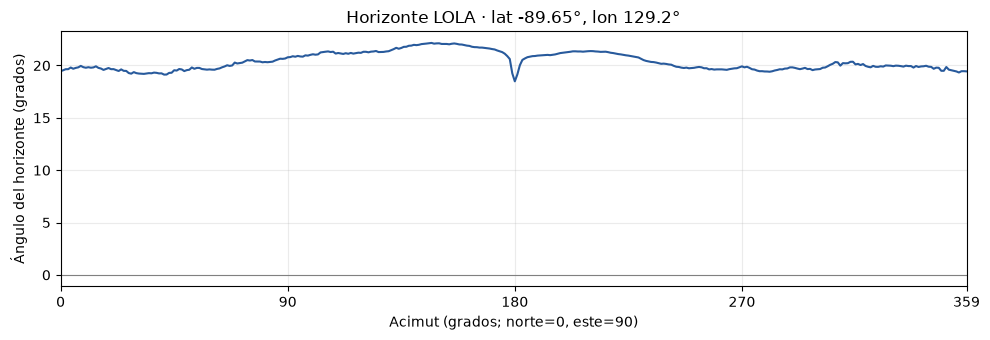

In [57]:
perfil = horizonte(datos, escala, LATITUD, LONGITUD, altura, RADIO_KM, PASO_M)
assert perfil.shape == (360,) and np.all(np.isfinite(perfil))
print("Shape:", perfil.shape)
print(f"Rango del horizonte: {perfil.min():.3f}° a {perfil.max():.3f}°")
print("Norte, este, sur y oeste:", perfil[[0, 90, 180, 270]])

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(np.arange(360), perfil, color="#285a9c", linewidth=1.5)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Acimut (grados; norte=0, este=90)",
       ylabel="Ángulo del horizonte (grados)", xlim=(0, 359),
       title=f"Horizonte LOLA · lat {LATITUD}°, lon {LONGITUD}°")
ax.set_xticks([0, 90, 180, 270, 359])
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Guardar el JSON con una sola llamada

`calcular_terreno` reúne los pasos anteriores y escribe el archivo. Recalcula con los mismos parámetros y reutiliza el mapa descargado; es la misma función que ejecuta el script.

JSON no tiene objetos NumPy: el array `(360,)` se guarda como una lista de 360 números. Se incluyen unos metadatos para poder interpretar el resultado en tu futuro script solar.

In [58]:
import importlib
import terreno_lola
importlib.reload(terreno_lola)

resultado = terreno_lola.calcular_terreno(
    LATITUD, LONGITUD, ppd=PPD, radio_km=RADIO_KM, paso_m=PASO_M, salida=SALIDA,
    radio_pendiente_m=RADIO_PENDIENTE_M, dem_local=DEM_LOCAL
)
np.testing.assert_allclose(resultado["horizonte_360"], perfil)
print("Archivo generado:", SALIDA.resolve())
print(json.dumps({k: v for k, v in resultado.items()
                  if k not in ("horizonte_360", "metadatos")}, indent=2, ensure_ascii=False))
print("horizonte_360 contiene", len(resultado["horizonte_360"]), "valores")

Archivo generado: C:\Users\Juan Manuel\Desktop\Carpetas\NASA_Hackathon_2026\LOLA_Terreno\terreno.json
{
  "latitud": -89.65,
  "longitud": 129.2,
  "elevacion_m": -2750.2200000000093,
  "pendiente_deg": 18.04956471831731
}
horizonte_360 contiene 360 valores


## 7. Ejecutar directamente el script

Desde la raíz del proyecto:

```bash
python LOLA_Terreno/terreno_lola.py --lat -89.65 --lon 129.2 --ppd 16 --salida LOLA_Terreno/terreno.json
```

La pendiente usa su propio radio: `--radio-pendiente-m 200`. Puedes indicar otro mapa con `--dem-local ruta.tif`. Si omites `--ppd`, el horizonte usa 64. Puedes añadir `--radio-km 300` o `--paso-m 100`.

Para recuperar el array en otro script:

```python
with open("LOLA_Terreno/terreno.json", encoding="utf-8") as f:
    terreno = json.load(f)
horizonte_deg = np.asarray(terreno["horizonte_360"])
```

## Límites que afectan al resultado

- Solo se examina relieve hasta el radio indicado. La ausencia de una montaña en este perfil no garantiza que no exista una más lejana.
- LOLA contiene zonas interpoladas entre medidas. La resolución del mapa no equivale a la precisión del horizonte real.
- Cerca de los polos, las celdas cilíndricas son muy estrechas este-oeste. El paso radial no garantiza captar todos los detalles. En las últimas semiceldas de latitud se usa el anillo más cercano; para estudios polares precisos conviene un DEM polar de mayor resolución.
- No hay pendientes subpíxel, altura de instrumentos, posición del Sol, tamaño del disco solar ni cálculo de iluminación. La comparación posterior con el Sol debe usar el mismo marco y la misma convención de acimut.

## Fuentes

- [Archivo oficial PDS: mapas LOLA globales](https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/cylindrical/img/).
- [Etiqueta LDEM_64: escala, radio, dimensiones y coordenadas](https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/cylindrical/img/ldem_64.lbl).
- [NASA PDS: documentación de LOLA](https://pds-geosciences.wustl.edu/missions/lro/lola.htm).

Registro de uso de IA: este notebook y su script fueron generados con ayuda de Codex para implementar y explicar el cálculo y añadir pendientes máximas en 200 m con recortes LOLA de mayor resolución.